In [1]:
import requests

url = "https://ckan0.cf.opendata.inter.prod-toronto.ca/api/3/action/package_show"
params = {"id": "traffic-volumes-midblock-vehicle-speed-volume-and-classification-counts"}

response = requests.get(url, params=params)
package = response.json()["result"]

for resource in package["resources"]:
    print(resource["name"], "|", resource["format"])

svc_most_recent_summary_data | CSV
svc_summary_data | CSV
fwha_classification.png | PNG
svc_data_dictionary.xlsx | XLSX
svc_raw_data_class_2000_2004 | CSV
svc_raw_data_class_2005_2009 | CSV
svc_raw_data_class_2010_2014 | CSV
svc_raw_data_class_2015_2019 | CSV
svc_raw_data_class_2020_2024 | CSV
svc_most_recent_summary_data.csv | CSV
svc_most_recent_summary_data.xml | XML
svc_most_recent_summary_data.json | JSON
svc_summary_data.csv | CSV
svc_summary_data.xml | XML
svc_summary_data.json | JSON
svc_raw_data_speed_1990_1994 | CSV
svc_raw_data_speed_1995_1999 | CSV
svc_raw_data_speed_2000_2004 | CSV
svc_raw_data_speed_2005_2009 | CSV
svc_raw_data_speed_2010_2014 | CSV
svc_raw_data_speed_2015_2019 | CSV
svc_raw_data_speed_2020_2024 | CSV
svc_raw_data_speed_2025_2029 | CSV
svc_raw_data_volume_1990_1994 | CSV
svc_raw_data_volume_1995_1999 | CSV
svc_raw_data_volume_2000_2004 | CSV
svc_raw_data_volume_2005_2009 | CSV
svc_raw_data_volume_2010_2014 | CSV
svc_raw_data_volume_2015_2019 | CSV
svc_raw

In [2]:
wanted = "svc_raw_data_volume_2020_2024"

for resource in package["resources"]:
    if resource["name"] == wanted:
        file_info = resource

head = requests.head(file_info["url"], allow_redirects=True)
size_mb = int(head.headers.get("Content-Length", 0)) / 1_000_000
print(f"File size: {size_mb:.0f} MB")

File size: 3 MB


In [3]:
import os

os.makedirs("data", exist_ok=True)

filename = file_info["url"].split("/")[-1]
save_path = os.path.join("data", filename)

download = requests.get(file_info["url"])
with open(save_path, "wb") as f:
    f.write(download.content)

print("Saved to:", save_path)
print(f"Size: {os.path.getsize(save_path) / 1_000_000:.1f} MB")

Saved to: data/svc_raw_data_volume_2020_2024.csv
Size: 2.5 MB


In [4]:
import pandas as pd

df = pd.read_csv(save_path)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (17568, 10)


,id,count_id,location_name,longitude,latitude,centreline_id,time_start,time_end,direction,volume_15min
0,3297012,2871638,Birch Ave: Lionel Conacher Park Trl - George H...,-79.394920,43.680700,30105718,2022-08-10 09:45:00,2022-08-10 10:00:00,EB,2
1,3223725,2850229,Old Foundry Rd: Rolling Mills Rd - St Lawrence St,-79.355825,43.654635,30043805,2021-05-13 00:00:00,2021-05-13 00:15:00,EB,3
2,3223726,2850229,Old Foundry Rd: Rolling Mills Rd - St Lawrence St,-79.355825,43.654635,30043805,2021-05-13 00:15:00,2021-05-13 00:30:00,EB,4
3,3223727,2850229,Old Foundry Rd: Rolling Mills Rd - St Lawrence St,-79.355825,43.654635,30043805,2021-05-13 00:30:00,2021-05-13 00:45:00,EB,5
4,3223728,2850229,Old Foundry Rd: Rolling Mills Rd - St Lawrence St,-79.355825,43.654635,30043805,2021-05-13 00:45:00,2021-05-13 01:00:00,EB,3


In [5]:
df["time_start"] = pd.to_datetime(df["time_start"])

print("Counting sessions:", df["count_id"].nunique())
print("Different streets:", df["location_name"].nunique())
print("Dates from", df["time_start"].min(), "to", df["time_start"].max())

rows_per_session = df.groupby("count_id").size()
print()
print("Biggest sessions (rows each):")
print(rows_per_session.sort_values(ascending=False).head(10))

Counting sessions: 40
Different streets: 27
Dates from 2021-04-27 00:00:00 to 2022-08-18 23:45:00

Biggest sessions (rows each):
count_id
2850229    1344
2851408    1344
2856386    1344
2850257    1344
2851380    1344
2850285    1344
2872382     576
2860056     576
2863434     576
2871638     576
dtype: int64


Old Foundry Rd: Rolling Mills Rd - St Lawrence St


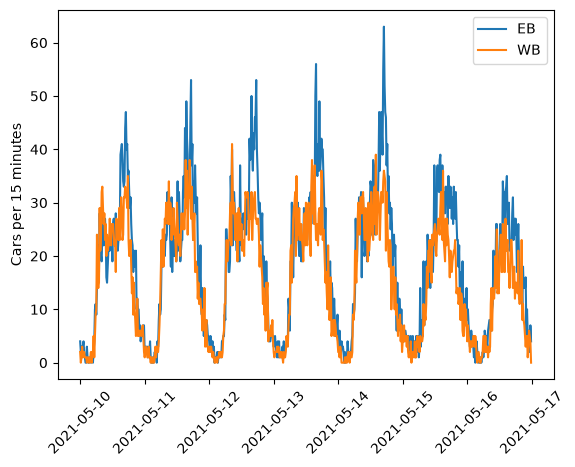

In [6]:
import matplotlib.pyplot as plt

one = df[df["count_id"] == 2850229]
print(one["location_name"].iloc[0])

for direction in one["direction"].unique():
    part = one[one["direction"] == direction].sort_values("time_start")
    plt.plot(part["time_start"], part["volume_15min"], label=direction)

plt.legend()
plt.ylabel("Cars per 15 minutes")
plt.xticks(rotation=45)
plt.show()

In [7]:
df = df.sort_values(["count_id", "direction", "time_start"]).reset_index(drop=True)

df["hour"] = df["time_start"].dt.hour + df["time_start"].dt.minute / 60
df["day_of_week"] = df["time_start"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df[["time_start", "hour", "day_of_week", "is_weekend", "volume_15min"]].head(8)

/var/folders/43/nlksrg793k9gwh2_ykbwqjhw0000gn/T/ipykernel_64291/426471022.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["time_start"].dt.dayofweek


,time_start,hour,day_of_week,is_weekend,volume_15min
0,2021-05-10 00:00:00,0.00,0,0,4
1,2021-05-10 00:15:00,0.25,0,0,2
2,2021-05-10 00:30:00,0.50,0,0,3
3,2021-05-10 00:45:00,0.75,0,0,3
4,2021-05-10 01:00:00,1.00,0,0,3
5,2021-05-10 01:15:00,1.25,0,0,4
6,2021-05-10 01:30:00,1.50,0,0,2
7,2021-05-10 01:45:00,1.75,0,0,1


In [8]:
group = df.groupby(["count_id", "direction"])["volume_15min"]

df["vol_15min_ago"] = group.shift(1)
df["vol_30min_ago"] = group.shift(2)
df["vol_45min_ago"] = group.shift(3)
df["vol_60min_ago"] = group.shift(4)

df[["time_start", "volume_15min", "vol_15min_ago", "vol_30min_ago", "vol_45min_ago", "vol_60min_ago"]].head(6)

,time_start,volume_15min,vol_15min_ago,vol_30min_ago,vol_45min_ago,vol_60min_ago
0,2021-05-10 00:00:00,4,NaN,NaN,NaN,NaN
1,2021-05-10 00:15:00,2,4.0,NaN,NaN,NaN
2,2021-05-10 00:30:00,3,2.0,4.0,NaN,NaN
3,2021-05-10 00:45:00,3,3.0,2.0,4.0,NaN
4,2021-05-10 01:00:00,3,3.0,3.0,2.0,4.0
5,2021-05-10 01:15:00,4,3.0,3.0,3.0,2.0


In [9]:
df["target_15min"] = group.shift(-1)
df["target_30min"] = group.shift(-2)
df["target_60min"] = group.shift(-4)

df[["time_start", "volume_15min", "target_15min", "target_30min", "target_60min"]].head(6)

,time_start,volume_15min,target_15min,target_30min,target_60min
0,2021-05-10 00:00:00,4,2.0,3.0,3.0
1,2021-05-10 00:15:00,2,3.0,3.0,4.0
2,2021-05-10 00:30:00,3,3.0,3.0,2.0
3,2021-05-10 00:45:00,3,3.0,4.0,1.0
4,2021-05-10 01:00:00,3,4.0,2.0,0.0
5,2021-05-10 01:15:00,4,2.0,1.0,0.0


In [10]:
features = ["hour", "day_of_week", "is_weekend", "volume_15min",
            "vol_15min_ago", "vol_30min_ago", "vol_45min_ago", "vol_60min_ago"]
targets = ["target_15min", "target_30min", "target_60min"]

print("Rows before:", len(df))
clean = df.dropna(subset=features + targets)
print("Rows after: ", len(clean))

Rows before: 17568
Rows after:  17128


In [11]:
import numpy as np

sessions = clean["count_id"].unique()
rng = np.random.default_rng(42)
test_sessions = rng.choice(sessions, size=8, replace=False)

test = clean[clean["count_id"].isin(test_sessions)]
train = clean[~clean["count_id"].isin(test_sessions)]

print("Train rows:", len(train), "| sessions:", train["count_id"].nunique())
print("Test rows: ", len(test), "| sessions:", test["count_id"].nunique())

Train rows: 12808 | sessions: 32
Test rows:  4320 | sessions: 8


In [12]:
for target in targets:
    error = (test[target] - test["volume_15min"]).abs().mean()
    print(f"{target}: lazy guess is off by {error:.2f} cars on average")

target_15min: lazy guess is off by 5.81 cars on average
target_30min: lazy guess is off by 6.46 cars on average
target_60min: lazy guess is off by 7.58 cars on average


In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
model.fit(train[features], train["target_15min"])

predictions = model.predict(test[features])
error = (test["target_15min"] - predictions).abs().mean()
print(f"Model is off by {error:.2f} cars on average (lazy guess: 5.81)")

Model is off by 5.06 cars on average (lazy guess: 5.81)


In [15]:
lazy_scores = {"target_15min": 5.81, "target_30min": 6.46, "target_60min": 7.58}
models = {}

for target in targets:
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
    model.fit(train[features], train[target])
    models[target] = model

    predictions = model.predict(test[features])
    error = (test[target] - predictions).abs().mean()
    better = (1 - error / lazy_scores[target]) * 100

    print(f"{target}: model {error:.2f} | lazy {lazy_scores[target]} | {better:.0f}% better")

target_15min: model 5.06 | lazy 5.81 | 13% better
target_30min: model 5.53 | lazy 6.46 | 14% better
target_60min: model 6.32 | lazy 7.58 | 17% better


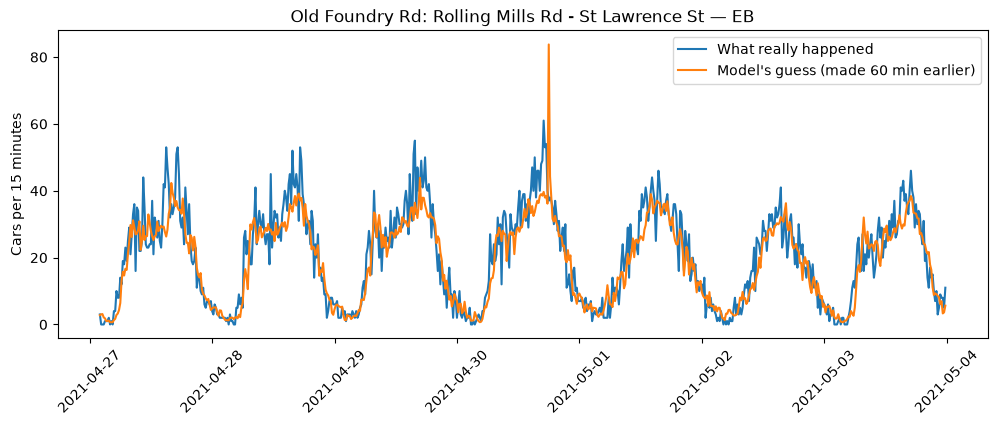

In [16]:
one_street = test[test["count_id"] == test_sessions[0]]
one_way = one_street[one_street["direction"] == one_street["direction"].iloc[0]].sort_values("time_start")

guesses = models["target_60min"].predict(one_way[features])
future_time = one_way["time_start"] + pd.Timedelta(minutes=60)

plt.figure(figsize=(12, 4))
plt.plot(future_time, one_way["target_60min"], label="What really happened")
plt.plot(future_time, guesses, label="Model's guess (made 60 min earlier)")
plt.title(one_way["location_name"].iloc[0] + " — " + one_way["direction"].iloc[0])
plt.ylabel("Cars per 15 minutes")
plt.legend()
plt.xticks(rotation=45)
plt.savefig("forecast.png", dpi=150, bbox_inches="tight")
plt.show()